# Momento Evaluativo II: Redes Neuronales Convolucionales
**Institución Universitaria ITM — Introducción al aprendizaje profundo**
**Docente:** Kevin Osorno Castillo


**Objetivo:** clasificar imágenes de 6 especies de aves con una Red Neuronal Convolucional diseñada e implementada desde cero en PyTorch.

El código está organizado en módulos reutilizables:

| Archivo | Contenido |
|---|---|
| `loader.py` | `BirdsDataset` (Dataset de PyTorch), `Loader` (división train/val/test + DataLoaders) |
| `model_cnn.py` | `CNNModel`, la CNN propia |
| `model_mlp.py` | `MLPModel`, usado para comparar el número de parámetros |
| `train_model.py` | Ciclo de entrenamiento / validación / predicción y curvas |
| `metrics.py` | Matriz de confusión y métricas de clasificación |

In [1]:
import os
import json
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image

from loader import BirdsDataset, Loader, get_data_dir
from model_cnn import CNNModel, count_parameters
from model_mlp import MLPModel
from train_model import set_seed, get_device, fit, evaluate, predict, plot_history, CHECKPOINT_DIR
import metrics

SEED = 42
set_seed(SEED)
device = get_device()

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option("display.precision", 4)

print(f"PyTorch {torch.__version__} | Dispositivo: {device}")

PyTorch 2.2.2 | Dispositivo: mps


## 1. Selección del conjunto de datos

| | |
|---|---|
| **Nombre** | *The Birds* |
| **Fuente** | Kaggle — usuario `figolm10` |
| **Enlace** | https://www.kaggle.com/datasets/figolm10/the-birds |
| **Descripción** | Colección de fotografías de 6 especies de aves con variedad de poses, fondos e iluminación. Cada especie está en su propia carpeta (una carpeta = una clase). |

El dataset no es CIFAR‑10 ni ninguno de los usados en las demostraciones de clase. Si no existe en `data/the-birds/`, `get_data_dir()` lo descarga con `kagglehub`.

In [2]:
data_dir = get_data_dir()
raw_dataset = BirdsDataset(data_dir)          # sin transformaciones: solo para explorar

counts = Counter(raw_dataset.targets)
df_counts = pd.DataFrame({
    "Clase": raw_dataset.classes,
    "Imágenes": [counts[i] for i in range(len(raw_dataset.classes))],
})
df_counts["%"] = 100 * df_counts["Imágenes"] / df_counts["Imágenes"].sum()

print(f"Ruta: {data_dir}")
print(f"Número total de imágenes: {len(raw_dataset)}")
print(f"Número de clases: {len(raw_dataset.classes)}")
df_counts

Ruta: /Users/jsrnieto/Documents/GitHub/DeepLearning.Momento.II/data/the-birds
Número total de imágenes: 811
Número de clases: 6


,Clase,Imágenes,%
0,AMERICAN GOLDFINCH,143,17.6326
1,BARN OWL,129,15.9063
2,CARMINE BEE-EATER,131,16.1529
3,DOWNY WOODPECKER,137,16.8927
4,EMPEROR PENGUIN,139,17.1393
5,FLAMINGO,132,16.2762


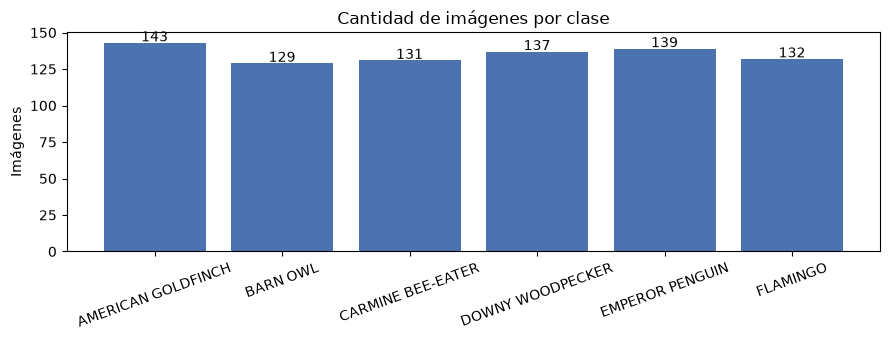

In [3]:
plt.figure(figsize=(9, 3.5))
plt.bar(df_counts["Clase"], df_counts["Imágenes"], color="#4C72B0")
for i, v in enumerate(df_counts["Imágenes"]):
    plt.text(i, v + 1, str(v), ha="center")
plt.title("Cantidad de imágenes por clase")
plt.ylabel("Imágenes")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/imagenes_por_clase.png", dpi=120)
plt.show()

In [4]:
# Dimensiones originales: se revisan TODAS las imágenes
sizes = Counter()
for path, _ in raw_dataset.samples:
    with Image.open(path) as img:
        sizes[(img.width, img.height, img.mode)] += 1

pd.DataFrame(
    [(w, h, mode, n) for (w, h, mode), n in sizes.items()],
    columns=["Ancho (W)", "Alto (H)", "Modo", "Imágenes"],
)

,Ancho (W),Alto (H),Modo,Imágenes
0,224,224,RGB,811


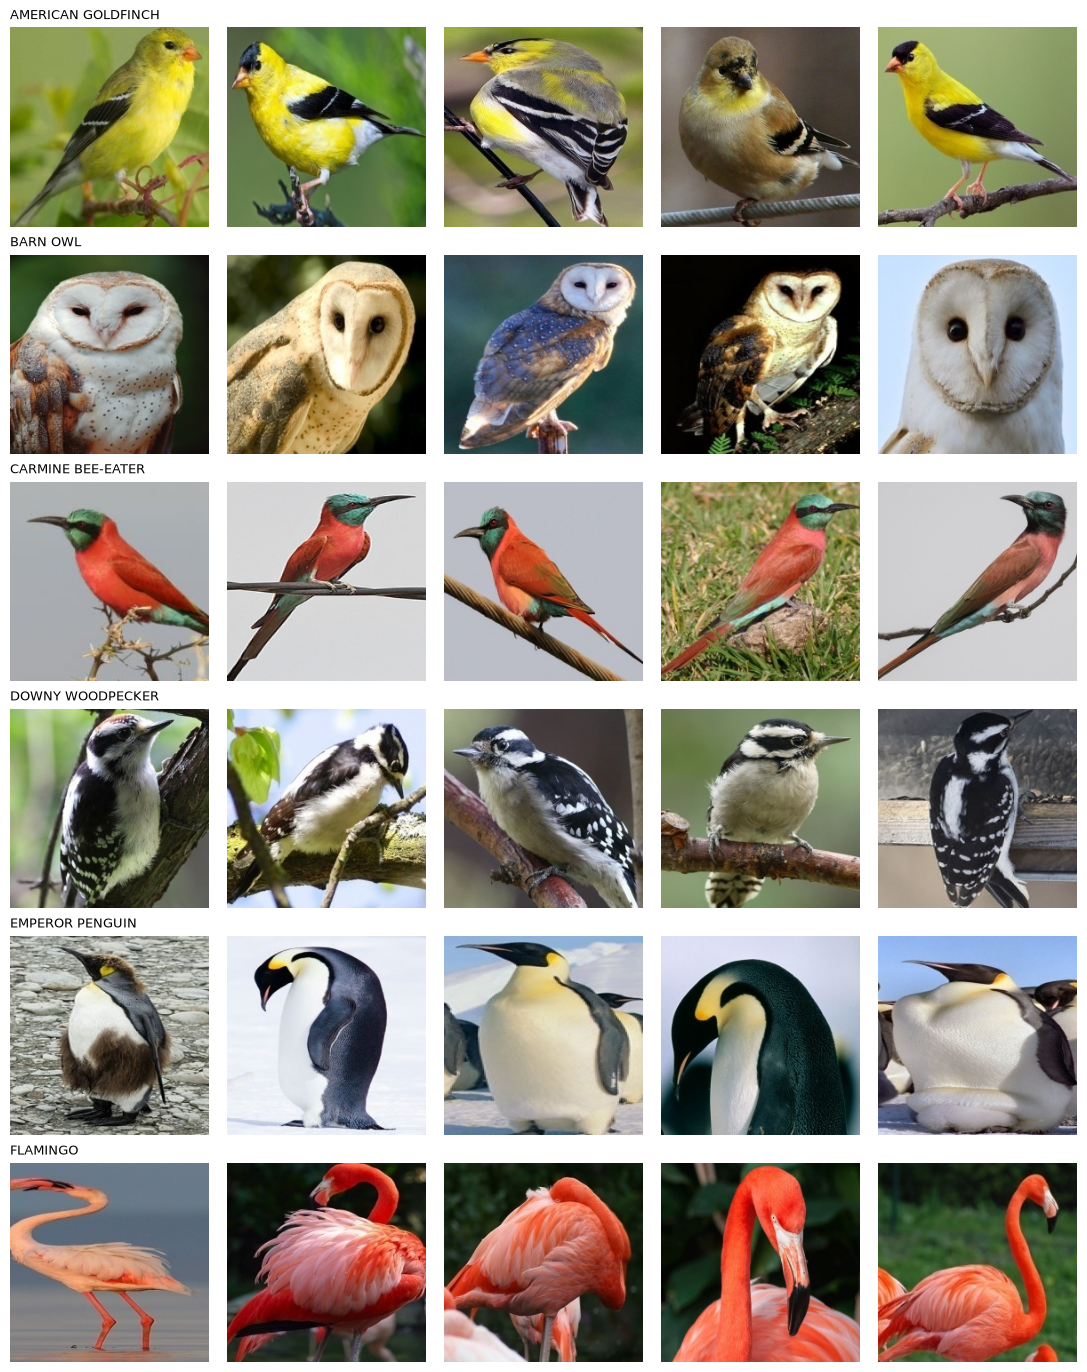

In [5]:
# Ejemplos visuales: 5 imágenes por clase
rng = np.random.default_rng(SEED)
n_cols = 5
fig, axes = plt.subplots(len(raw_dataset.classes), n_cols, figsize=(2.2 * n_cols, 2.3 * len(raw_dataset.classes)))
targets = np.array(raw_dataset.targets)

for c, clase in enumerate(raw_dataset.classes):
    idxs = rng.choice(np.where(targets == c)[0], n_cols, replace=False)
    for k, idx in enumerate(idxs):
        image, _ = raw_dataset[idx]
        axes[c, k].imshow(image)
        axes[c, k].axis("off")
    axes[c, 0].set_title(clase, fontsize=9, loc="left")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/ejemplos_dataset.png", dpi=120)
plt.show()

### ¿Por qué este conjunto de datos puede abordarse con una CNN?

- **Es un problema de clasificación de imágenes**: cada imagen RGB tiene una única etiqueta (la especie).
- **La información es espacial**: lo que distingue a las especies son patrones visuales como el color y la textura del plumaje, la forma del pico, el disco facial del búho, el contraste blanco/negro del pingüino o el cuello largo y rosado del flamenco. Una CNN detecta exactamente este tipo de patrones locales con filtros que recorren la imagen, preservando la relación espacial entre píxeles (que un MLP perdería al aplanar la imagen).
- **El ave aparece en distintas posiciones, poses y fondos**: gracias a los **pesos compartidos**, el mismo filtro detecta un patrón (p. ej. un ojo o una textura de plumas) en cualquier parte de la imagen, y el pooling aporta cierta invariancia a pequeñas traslaciones.
- **Tamaño manejable**: 811 imágenes de 224×224 RGB, con clases casi balanceadas (129–143 por clase), suficientes para separar entrenamiento, validación y prueba y entrenar una CNN pequeña en CPU/GPU de portátil.

## 2. Preparación de los datos

1. **División**: como el dataset no trae particiones, se hace una división **estratificada** (misma proporción de cada clase en cada conjunto) con semilla fija:
   **70 % entrenamiento / 15 % validación / 15 % prueba**.
2. **Dimensiones consistentes**: todas las imágenes se redimensionan a **128×128** (las originales son 224×224; 128 reduce ~3× el costo computacional manteniendo detalle suficiente del ave).
3. **Transformaciones** (únicamente las permitidas):
   - `Resize((128, 128))` — cambio de tamaño.
   - `ToTensor()` — convierte la imagen PIL `[H, W, C]` con valores 0–255 a tensor `[C, H, W]` con valores en [0, 1].
   - `Normalize(mean, std)` — estandariza cada canal; **la media y la desviación estándar se calculan solo con el conjunto de entrenamiento** para no filtrar información de validación/prueba.

In [6]:
IMG_SIZE   = 128
BATCH_SIZE = 32

loader = Loader(root_dir=data_dir, img_size=IMG_SIZE, splits=(0.70, 0.15, 0.15), seed=SEED)
classes = loader.classes

df_split = pd.DataFrame(loader.split_counts())
df_split.loc["Total"] = df_split.sum()
df_split["Total"] = df_split.sum(axis=1)
total = df_split.loc["Total", "Total"]
print("Proporciones:", {k: f"{100 * df_split.loc['Total', k] / total:.1f}%" for k in ["train", "val", "test"]})
print("Transformaciones:", loader.transform)
print(f"Media (train): {np.round(loader.mean, 4)} | Desv. estándar (train): {np.round(loader.std, 4)}")
df_split

Proporciones: {'train': '69.9%', 'val': '15.0%', 'test': '15.0%'}
Transformaciones: Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.5093597769737244, 0.4955000877380371, 0.43292638659477234], std=[0.2577345669269562, 0.24858081340789795, 0.2810184359550476])
)
Media (train): [0.5094 0.4955 0.4329] | Desv. estándar (train): [0.2577 0.2486 0.281 ]


,train,val,test,Total
AMERICAN GOLDFINCH,100,21,22,143
BARN OWL,90,20,19,129
CARMINE BEE-EATER,92,19,20,131
DOWNY WOODPECKER,96,21,20,137
EMPEROR PENGUIN,97,21,21,139
FLAMINGO,92,20,20,132
Total,567,122,122,811


In [7]:
train_loader = loader.train_loader(batch_size=BATCH_SIZE)
val_loader   = loader.val_loader(batch_size=BATCH_SIZE)
test_loader  = loader.test_loader(batch_size=BATCH_SIZE)

images, labels = next(iter(train_loader))
print(f"Tensor de imágenes [B, C, H, W]: {list(images.shape)}  dtype={images.dtype}")
print(f"Tensor de etiquetas [B]:          {list(labels.shape)}  dtype={labels.dtype}")
print(f"Rango de valores tras Normalize: [{images.min():.2f}, {images.max():.2f}]")

Tensor de imágenes [B, C, H, W]: [32, 3, 128, 128]  dtype=torch.float32
Tensor de etiquetas [B]:          [32]  dtype=torch.int64
Rango de valores tras Normalize: [-1.99, 2.03]


**Dimensiones finales de entrada a la red: `[B, C, H, W] = [32, 3, 128, 128]`**

| Componente | Valor | Significado |
|---|---|---|
| **B** | 32 | *Batch size*: número de imágenes procesadas a la vez (el último lote puede ser menor). |
| **C** | 3 | Canales de color (R, G, B). |
| **H** | 128 | Alto de la imagen en píxeles. |
| **W** | 128 | Ancho de la imagen en píxeles. |

Las etiquetas son un tensor `[B]` de enteros (0–5) con el índice de la clase, que es lo que espera `CrossEntropyLoss`.

## 3. Diseño de la arquitectura CNN

Arquitectura propia con **4 bloques convolucionales** (`Conv → BatchNorm → ReLU → MaxPool`) y un clasificador de **2 capas completamente conectadas**. Se construye solo con capas básicas de PyTorch (`nn.Conv2d`, `nn.BatchNorm2d`, `nn.ReLU`, `nn.MaxPool2d`, `nn.Dropout`, `nn.Linear`).

Tamaño de salida de cada convolución/pooling (fórmula vista en clase):

$$\text{Output} = \left\lfloor \frac{\text{input} - \text{kernel} + 2\cdot\text{padding}}{\text{stride}} \right\rfloor + 1$$

- Conv 3×3, padding 1, stride 1: $(128 - 3 + 2)/1 + 1 = 128$ → conserva el tamaño ("same").
- MaxPool 2×2, stride 2: $(128 - 2)/2 + 1 = 64$ → reduce a la mitad.

| Capa | Configuración | Dimensión de salida |
|---|---|---|
| Entrada | Imagen RGB normalizada | `[B, 3, 128, 128]` |
| Conv1 + BN + ReLU | 32 filtros, kernel 3×3, stride 1, padding 1 (entrada 3 canales) | `[B, 32, 128, 128]` |
| Pool1 | MaxPool 2×2, stride 2 | `[B, 32, 64, 64]` |
| Conv2 + BN + ReLU | 64 filtros, kernel 3×3, stride 1, padding 1 (entrada 32) | `[B, 64, 64, 64]` |
| Pool2 | MaxPool 2×2, stride 2 | `[B, 64, 32, 32]` |
| Conv3 + BN + ReLU | 128 filtros, kernel 3×3, stride 1, padding 1 (entrada 64) | `[B, 128, 32, 32]` |
| Pool3 + Dropout2d | MaxPool 2×2, stride 2; Dropout2d p=0.2 | `[B, 128, 16, 16]` |
| Conv4 + BN + ReLU | 256 filtros, kernel 3×3, stride 1, padding 1 (entrada 128) | `[B, 256, 16, 16]` |
| Pool4 + Dropout2d | MaxPool 2×2, stride 2; Dropout2d p=0.2 | `[B, 256, 8, 8]` |
| Flatten | 256 × 8 × 8 | `[B, 16384]` |
| Linear (FC1) + ReLU + Dropout | 16384 → 128 neuronas; Dropout p=0.5 | `[B, 128]` |
| Salida (FC2) | 128 → 6 neuronas (logits; softmax implícito en `CrossEntropyLoss`) | `[B, 6]` |

**Decisiones de diseño**
- **Kernels 3×3 con padding 1**: filtros pequeños con pocos parámetros; el padding evita perder los bordes y deja que solo el pooling controle la reducción espacial.
- **Número de filtros creciente (32→64→128→256)**: mientras la resolución baja a la mitad en cada bloque, se aumenta la cantidad de mapas de características para representar patrones cada vez más complejos.
- **4 bloques (uno más que el ejemplo de CIFAR‑10)**: las imágenes son de 128×128 (4× más grandes por lado que CIFAR), por lo que se necesita más profundidad para que el campo receptivo cubra partes completas del ave y para llevar el mapa final a 8×8.
- **BatchNorm**: estabiliza y acelera el entrenamiento normalizando las activaciones de cada capa.
- **Dropout / Dropout2d y weight decay**: el dataset es pequeño (567 imágenes de entrenamiento) y sin augmentation, así que el riesgo de sobreajuste es alto; estas técnicas regularizan el modelo.

In [8]:
model = CNNModel(num_classes=len(classes), in_channels=3, img_size=IMG_SIZE).to(device)
print(model)
print(f"\nParámetros entrenables: {count_parameters(model):,}")

CNNModel(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout_conv): Dropout2d(p=0.2, inplace=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=6, bias=True)
  (relu): ReLU()
)



In [9]:
# Verificación de las dimensiones capa por capa con un tensor de ejemplo
def layer_table(model, img_size):
    m = CNNModel(num_classes=len(classes), img_size=img_size).eval()
    m.load_state_dict({k: v.cpu() for k, v in model.state_dict().items()})
    x = torch.zeros(1, 3, img_size, img_size)
    rows = [("Entrada", list(x.shape), 0)]
    nparams = lambda *mods: sum(p.numel() for mod in mods for p in mod.parameters())
    for i in range(1, 5):
        conv, bn = getattr(m, f"conv{i}"), getattr(m, f"bn{i}")
        x = m.relu(bn(conv(x)))
        rows.append((f"Conv{i} + BN + ReLU", list(x.shape), nparams(conv, bn)))
        x = m.pool(x)
        rows.append((f"Pool{i}", list(x.shape), 0))
    x = torch.flatten(x, 1); rows.append(("Flatten", list(x.shape), 0))
    x = m.relu(m.fc1(x));     rows.append(("FC1 + ReLU", list(x.shape), nparams(m.fc1)))
    x = m.fc2(x);             rows.append(("FC2 (salida)", list(x.shape), nparams(m.fc2)))
    df = pd.DataFrame(rows, columns=["Capa", "Salida [B, C, H, W]", "Parámetros"])
    df["Salida [B, C, H, W]"] = df["Salida [B, C, H, W]"].astype(str).str.replace("[1,", "[B,", regex=False)
    return df

df_layers = layer_table(model, IMG_SIZE)
print(f"Total: {df_layers['Parámetros'].sum():,} parámetros")
df_layers

Total: 2,487,430 parámetros


,Capa,"Salida [B, C, H, W]",Parámetros
0,Entrada,"[B, 3, 128, 128]",0
1,Conv1 + BN + ReLU,"[B, 32, 128, 128]",960
2,Pool1,"[B, 32, 64, 64]",0
3,Conv2 + BN + ReLU,"[B, 64, 64, 64]",18624
4,Pool2,"[B, 64, 32, 32]",0
5,Conv3 + BN + ReLU,"[B, 128, 32, 32]",74112
6,Pool3,"[B, 128, 16, 16]",0
7,Conv4 + BN + ReLU,"[B, 256, 16, 16]",295680
8,Pool4,"[B, 256, 8, 8]",0
9,Flatten,"[B, 16384]",0


## 4. Entrenamiento

| Hiperparámetro | Valor | Justificación |
|---|---|---|
| Función de pérdida | `CrossEntropyLoss` | Clasificación multiclase (6 clases); combina softmax + log‑verosimilitud negativa. |
| Optimizador | `Adam` | Tasa de aprendizaje adaptativa por parámetro; converge rápido sin mucho ajuste. |
| Learning rate | `1e-3` | Valor estándar para Adam. |
| Weight decay | `1e-4` | Regularización L2 para reducir sobreajuste. |
| Batch size | `32` | Compromiso entre estabilidad del gradiente y memoria con un dataset pequeño. |
| Número de épocas | `40` | Suficientes para observar convergencia y el inicio del sobreajuste. |

En cada época se registran **Training Loss, Training Accuracy, Validation Loss y Validation Accuracy**. Se conservan los pesos de la época con **menor Validation Loss** (*checkpoint*), que es la que se usa después en el conjunto de prueba. El conjunto de prueba **no** se usa durante el entrenamiento.

In [10]:
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 1e-4
NUM_EPOCHS    = 40

set_seed(SEED)
model = CNNModel(num_classes=len(classes), img_size=IMG_SIZE).to(device)

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

history = fit(
    model, train_loader, val_loader, criterion, optimizer, device, NUM_EPOCHS,
    checkpoint_path=os.path.join(CHECKPOINT_DIR, "best_cnn.pt"),
)

with open(f"{FIG_DIR}/history.json", "w") as f:
    json.dump(history, f, indent=2)

print(f"\nMejor época (menor Val Loss): {history['best_epoch']}  -> Val Loss = {history['best_val_loss']:.4f}")

Epoch [1/40] Train Loss: 2.8694 Train Acc: 35.27% Val Loss: 0.9716 Val Acc: 68.85% *
Epoch [2/40] Train Loss: 0.9308 Train Acc: 66.31% Val Loss: 0.6769 Val Acc: 77.05% *
Epoch [3/40] Train Loss: 0.6884 Train Acc: 75.84% Val Loss: 0.6311 Val Acc: 80.33% *
Epoch [4/40] Train Loss: 0.5808 Train Acc: 80.78% Val Loss: 0.5560 Val Acc: 79.51% *
Epoch [5/40] Train Loss: 0.5632 Train Acc: 81.48% Val Loss: 0.3729 Val Acc: 86.89% *
Epoch [6/40] Train Loss: 0.3995 Train Acc: 87.13% Val Loss: 0.3662 Val Acc: 87.70% *
Epoch [7/40] Train Loss: 0.4029 Train Acc: 85.54% Val Loss: 0.7238 Val Acc: 75.41%
Epoch [8/40] Train Loss: 0.4138 Train Acc: 85.36% Val Loss: 0.3273 Val Acc: 85.25% *
Epoch [9/40] Train Loss: 0.3531 Train Acc: 87.13% Val Loss: 0.4083 Val Acc: 86.89%
Epoch [10/40] Train Loss: 0.3284 Train Acc: 90.48% Val Loss: 0.3320 Val Acc: 87.70%
Epoch [11/40] Train Loss: 0.2961 Train Acc: 91.01% Val Loss: 0.4304 Val Acc: 87.70%
Epoch [12/40] Train Loss: 0.3733 Train Acc: 86.07% Val Loss: 0.4365 Val

In [11]:
df_hist = pd.DataFrame({k: history[k] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]})
df_hist.index = df_hist.index + 1
df_hist.index.name = "Época"
df_hist.columns = ["Training Loss", "Training Acc (%)", "Validation Loss", "Validation Acc (%)"]
df_hist.style.format("{:.4f}").highlight_min(subset=["Validation Loss"], color="#c6efce").highlight_max(subset=["Validation Acc (%)"], color="#c6efce")

,Training Loss,Training Acc (%),Validation Loss,Validation Acc (%)
Época,,,,
1,2.8694,35.2734,0.9716,68.8525
2,0.9308,66.3139,0.6769,77.0492
3,0.6884,75.8377,0.6311,80.3279
4,0.5808,80.7760,0.5560,79.5082
5,0.5632,81.4815,0.3729,86.8852
6,0.3995,87.1252,0.3662,87.7049
7,0.4029,85.5379,0.7238,75.4098
8,0.4138,85.3616,0.3273,85.2459
9,0.3531,87.1252,0.4083,86.8852


## 5. Análisis del entrenamiento

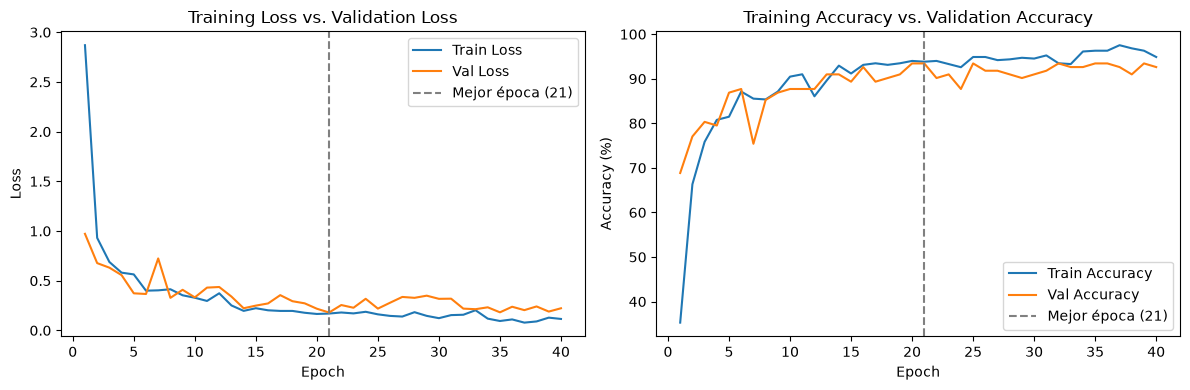

In [12]:
plot_history(history, path=f"{FIG_DIR}/loss_accuracy_plot.png")

In [13]:
best = history["best_epoch"]
best_acc_epoch = int(np.argmax(history["val_acc"])) + 1
summary = pd.DataFrame({
    "Época": [best, best_acc_epoch, NUM_EPOCHS],
    "Train Loss": [history["train_loss"][e - 1] for e in [best, best_acc_epoch, NUM_EPOCHS]],
    "Val Loss": [history["val_loss"][e - 1] for e in [best, best_acc_epoch, NUM_EPOCHS]],
    "Train Acc (%)": [history["train_acc"][e - 1] for e in [best, best_acc_epoch, NUM_EPOCHS]],
    "Val Acc (%)": [history["val_acc"][e - 1] for e in [best, best_acc_epoch, NUM_EPOCHS]],
}, index=["Menor Val Loss", "Mayor Val Acc", "Última época"])
summary["Brecha Acc (train - val)"] = summary["Train Acc (%)"] - summary["Val Acc (%)"]
summary

,Época,Train Loss,Val Loss,Train Acc (%),Val Acc (%),Brecha Acc (train - val)
Menor Val Loss,21,0.1694,0.1798,93.8272,93.4426,0.3845
Mayor Val Acc,20,0.1652,0.2179,94.0035,93.4426,0.5609
Última época,40,0.1151,0.2225,94.8854,92.6230,2.2624


> *Los valores citados corresponden a la ejecución guardada en este notebook. El entrenamiento en GPU (MPS) no es 100 % determinista, por lo que una nueva ejecución puede variar ligeramente.*

**1. ¿En qué época el modelo presenta su mejor comportamiento sobre datos no vistos en el entrenamiento?**

En la **época 21**, que tiene la **menor Validation Loss (0,180)** con una **Validation Accuracy de 93,4 %** (Training Accuracy 93,8 %). La época 20 alcanza la misma accuracy de validación, pero con una pérdida mayor (0,218), es decir, con predicciones menos seguras; por eso se elige la pérdida como criterio. Los pesos de esta época se guardaron como *checkpoint* (`checkpoints/best_cnn.pt`) y son los que se evalúan en el conjunto de prueba.

**2. ¿Qué diferencias se observan entre entrenamiento y validación?**

- **Primeras épocas (1–5): la validación es mejor que el entrenamiento.** La métrica de entrenamiento es el promedio de toda la época, mientras los pesos todavía cambian rápido (la Training Loss de la época 1 es 2,87 por los pesos aleatorios iniciales), y además se calcula con Dropout activo. La validación se mide al final de la época en modo `eval()`, sin Dropout.
- **La curva de validación es más ruidosa** (por ejemplo, en la época 7 cae a 75,4 %). El conjunto de validación tiene solo 122 imágenes, así que cada imagen equivale a ~0,8 puntos porcentuales; además, con un learning rate fijo de 1e‑3 los pesos oscilan alrededor del mínimo.
- **A partir de la época ~21 aparece un sobreajuste leve:** la Training Loss sigue bajando (0,17 → 0,08 en la época 37) y la Training Accuracy sube hasta 97,5 %, mientras la Validation Loss deja de mejorar y oscila entre 0,18 y 0,35. La brecha de accuracy sigue siendo pequeña (≈ 0,4 pp en la mejor época y ≈ 2,3 pp en la última), gracias a BatchNorm, Dropout y weight decay. El modelo generaliza bien, pero entrenar más épocas ya no aporta.

**3. ¿Qué modificaciones se podrían hacer para intentar mejorar el modelo?**

- **Early stopping** con paciencia (p. ej. 8 épocas sin mejorar la Validation Loss) para detenerse cerca de la época 21 y ahorrar cómputo (hoy ya se guarda el mejor checkpoint).
- **Scheduler de learning rate** (`ReduceLROnPlateau` o *cosine annealing*) para reducir las oscilaciones de la validación cuando el modelo se acerca al mínimo.
- **Reemplazar Flatten + FC1 por Global Average Pooling**: FC1 tiene 2,10 M de los 2,49 M de parámetros (84 %). Con GAP el clasificador pasaría a recibir 256 valores, reduciendo mucho los parámetros y el riesgo de sobreajuste.
- **Bloques más profundos** (dos convoluciones 3×3 por bloque antes de cada pooling) o una resolución mayor (160–224 px) para capturar detalles finos de plumaje, y así distinguir especies con colores parecidos (los errores de la sección 6 se deben justamente al color).
- **Ajustar la regularización** (probabilidad de Dropout, weight decay, *label smoothing*) con búsqueda de hiperparámetros sobre el conjunto de validación.
- **Validación cruzada estratificada (k‑fold)**: con solo 811 imágenes, la estimación sobre 122 imágenes de validación tiene bastante varianza.
- **Más datos**: conseguir más imágenes reales por especie. *Data augmentation* sería la opción habitual, pero está prohibido en esta actividad, así que no se usó.

## 6. Evaluación sobre el conjunto de prueba

El conjunto de prueba se usa **solo ahora**, una vez cerradas la arquitectura y el entrenamiento, con los pesos de la mejor época según validación.

In [14]:
model.load_state_dict(torch.load(os.path.join(CHECKPOINT_DIR, "best_cnn.pt"), map_location=device))

test_loss, test_acc = evaluate(model, test_loader, criterion, device)
y_true, y_pred, y_prob = predict(model, test_loader, device)

print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.2f}% ({(y_true == y_pred).sum()}/{len(y_true)})")

Test Loss: 0.1266 | Test Accuracy: 95.90% (117/122)


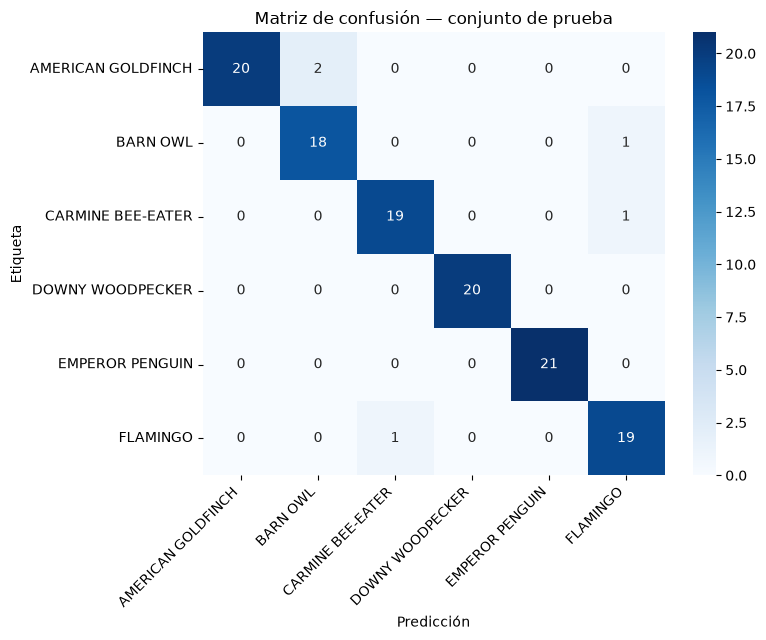

In [15]:
cm = metrics.plot_confusion_matrix(y_true, y_pred, classes, path=f"{FIG_DIR}/matriz_confusion.png",
                                   title="Matriz de confusión — conjunto de prueba")

### Métricas de clasificación

Para un problema multiclase cada métrica se calcula tomando **una clase como positiva y el resto como negativas** (*one‑vs‑rest*), a partir de la matriz de confusión:

- **Accuracy** $= \frac{TP+TN}{TP+TN+FP+FN}$ — proporción total de aciertos.
- **Precision** $= \frac{TP}{TP+FP}$ — de las veces que el modelo predijo la clase, cuántas acertó.
- **Recall / Sensibilidad** $= \frac{TP}{TP+FN}$ — de las imágenes de la clase, cuántas detectó.
- **Especificidad** $= \frac{TN}{TN+FP}$ — qué tan bien reconoce que una imagen *no* es de la clase.
- **Tasa de falsos positivos** $= \frac{FP}{FP+TN}$ y **tasa de falsos negativos** $= \frac{FN}{FN+TP}$.
- **F1‑Score** $= 2\cdot\frac{Precision \cdot Recall}{Precision + Recall}$.
- **AUC‑ROC** — área bajo la curva ROC (sensibilidad vs. 1 − especificidad al variar el umbral), calculada con las probabilidades softmax.

In [16]:
metrics.summary_metrics(y_true, y_pred, y_prob, classes).to_frame("Valor")

,Valor
Accuracy,0.9590
Precision (macro),0.9591
Recall (macro),0.9594
F1-Score (macro),0.9587
AUC-ROC (macro OvR),0.9980


In [17]:
df_ovr = metrics.one_vs_rest_metrics(cm, classes)
df_ovr

,TP,FP,FN,TN,Precision,Recall (Sensibilidad),Especificidad,Tasa FP,Tasa FN,F1-Score
Clase,,,,,,,,,,
AMERICAN GOLDFINCH,20,0,2,100,1.0000,0.9091,1.0000,0.0000,0.0909,0.9524
BARN OWL,18,2,1,101,0.9000,0.9474,0.9806,0.0194,0.0526,0.9231
CARMINE BEE-EATER,19,1,1,101,0.9500,0.9500,0.9902,0.0098,0.0500,0.9500
DOWNY WOODPECKER,20,0,0,102,1.0000,1.0000,1.0000,0.0000,0.0000,1.0000
EMPEROR PENGUIN,21,0,0,101,1.0000,1.0000,1.0000,0.0000,0.0000,1.0000
FLAMINGO,19,2,1,100,0.9048,0.9500,0.9804,0.0196,0.0500,0.9268


In [18]:
metrics.report(y_true, y_pred, classes)

,precision,recall,f1-score,support
AMERICAN GOLDFINCH,1.0000,0.9091,0.9524,22.000
BARN OWL,0.9000,0.9474,0.9231,19.000
CARMINE BEE-EATER,0.9500,0.9500,0.9500,20.000
DOWNY WOODPECKER,1.0000,1.0000,1.0000,20.000
EMPEROR PENGUIN,1.0000,1.0000,1.0000,21.000
FLAMINGO,0.9048,0.9500,0.9268,20.000
accuracy,0.9590,0.9590,0.9590,0.959
macro avg,0.9591,0.9594,0.9587,122.000
weighted avg,0.9606,0.9590,0.9592,122.000


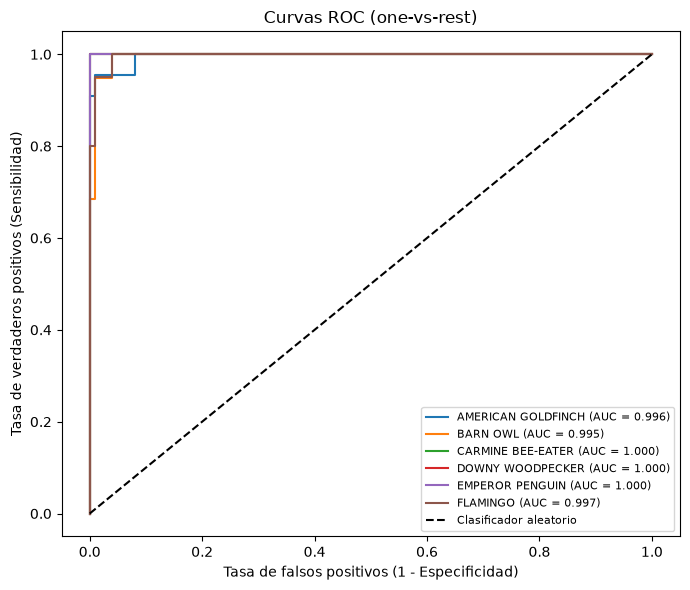

In [19]:
metrics.plot_roc_curves(y_true, y_prob, classes, path=f"{FIG_DIR}/curvas_roc.png")

### Predicciones correctas e incorrectas

Correctas: 117 | Incorrectas: 5


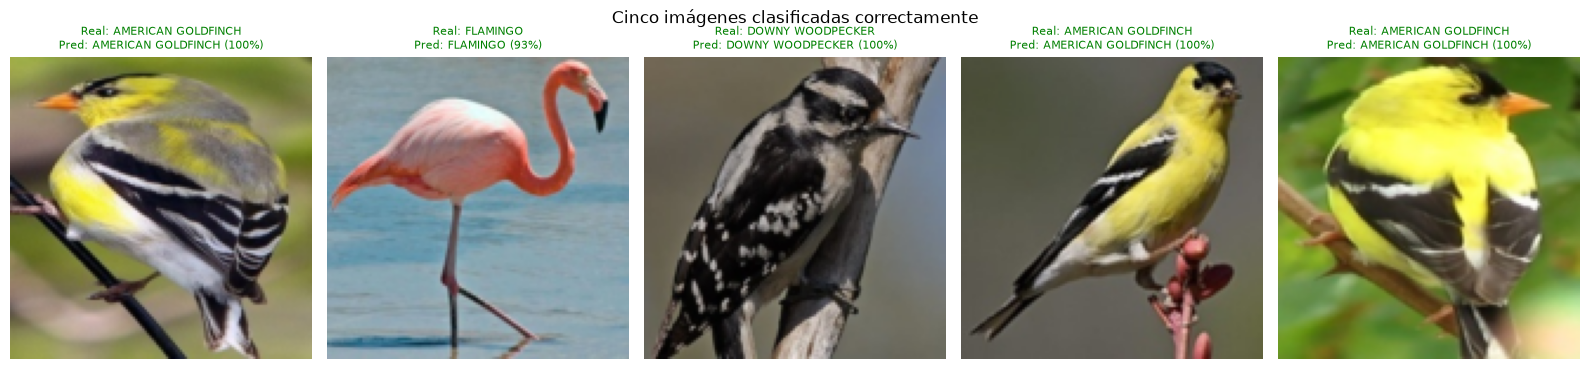

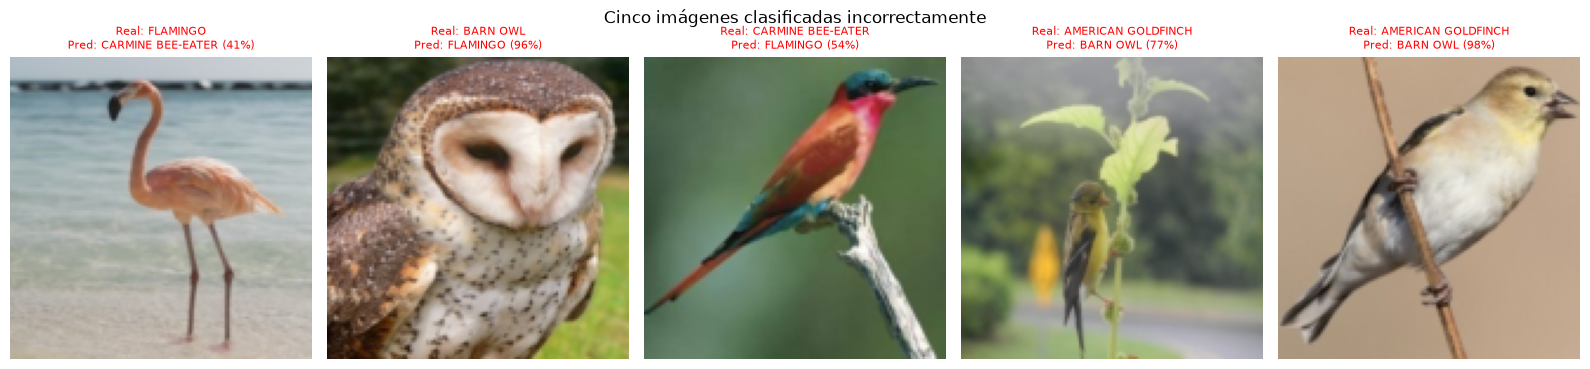

In [20]:
correct_pos   = np.where(y_true == y_pred)[0]
incorrect_pos = np.where(y_true != y_pred)[0]
print(f"Correctas: {len(correct_pos)} | Incorrectas: {len(incorrect_pos)}")

rng = np.random.default_rng(SEED)
sel_correct   = rng.choice(correct_pos, min(5, len(correct_pos)), replace=False)
sel_incorrect = rng.choice(incorrect_pos, min(5, len(incorrect_pos)), replace=False)

metrics.show_predictions(loader.test_dataset, sel_correct, y_true, y_pred, y_prob, classes,
                         loader.mean, loader.std, "Cinco imágenes clasificadas correctamente",
                         path=f"{FIG_DIR}/predicciones_correctas.png")
metrics.show_predictions(loader.test_dataset, sel_incorrect, y_true, y_pred, y_prob, classes,
                         loader.mean, loader.std, "Cinco imágenes clasificadas incorrectamente",
                         path=f"{FIG_DIR}/predicciones_incorrectas.png")

In [21]:
print("Pares de clases más confundidos (real -> predicha):")
metrics.top_confusions(cm, classes, k=6)

Pares de clases más confundidos (real -> predicha):


,Clase real,Clase predicha,Errores
0,AMERICAN GOLDFINCH,BARN OWL,2
1,BARN OWL,FLAMINGO,1
2,CARMINE BEE-EATER,FLAMINGO,1
3,FLAMINGO,CARMINE BEE-EATER,1


### Resultados en prueba

- **Accuracy: 95,9 %** (117 de 122 imágenes), Test Loss 0,127. Es coherente con la validación (93,4 %), así que no hay señales de que el modelo se haya ajustado al conjunto de validación.
- **Precision, Recall y F1 macro ≈ 0,96** y **AUC‑ROC macro (one‑vs‑rest) = 0,998**: aun en los casos donde la clase final es incorrecta, las probabilidades ordenan casi perfectamente las imágenes positivas por encima de las negativas.
- **Especificidad ≥ 0,98 en todas las clases**: casi no hay falsas alarmas. Las clases con más falsos positivos son BARN OWL y FLAMINGO (2 FP cada una), que tienen la menor precisión (0,90).
- **DOWNY WOODPECKER y EMPEROR PENGUIN se clasifican perfectamente** (F1 = 1,0): tienen patrones muy distintivos (contraste blanco/negro con manchas, silueta del pingüino sobre hielo/nieve).
- AMERICAN GOLDFINCH tiene el menor recall (0,91): 2 de sus 22 imágenes se predicen como otra clase.

### ¿Existen clases que el modelo tienda a confundir entre sí?

Sí, aunque con pocos errores (5 en total). Los patrones son claros y se deben sobre todo al **color dominante**:

1. **AMERICAN GOLDFINCH → BARN OWL (2 errores).** Ambas imágenes son jilgueros con plumaje pálido (hembra o plumaje de invierno), de tonos beige, blancos y marrones, la misma paleta que la lechuza; en una de ellas el ave además es pequeña y está sobre un fondo con mucha vegetación. El modelo aprendió a asociar el **amarillo intenso** con el jilguero, y cuando ese color no está, se equivoca.
2. **FLAMINGO ↔ CARMINE BEE‑EATER (1 error en cada dirección).** Las dos especies tienen tonos **rosados/rojizos**. El flamenco se confundió con baja confianza (41 %) y el abejaruco con 54 %: el modelo "dudaba" entre ambas clases.
3. **BARN OWL → FLAMINGO (1 error, 96 % de confianza).** Es un primer plano del rostro del búho con plumas color crema/rosado. A esa escala la red no ve la silueta completa y se basa en el color y la textura, lo que la lleva a un error con mucha confianza.

**Conclusión:** la red se apoya mucho en la paleta de color y en texturas, y menos en la forma global del ave. Las confusiones aparecen entre especies con colores parecidos o cuando la especie no muestra su color típico.

## 7. Preguntas de análisis

Para apoyar la Pregunta 1 se visualizan algunos **mapas de características** de cada bloque convolucional para una imagen de prueba (como en las diapositivas "¿Qué ven las CNN?").

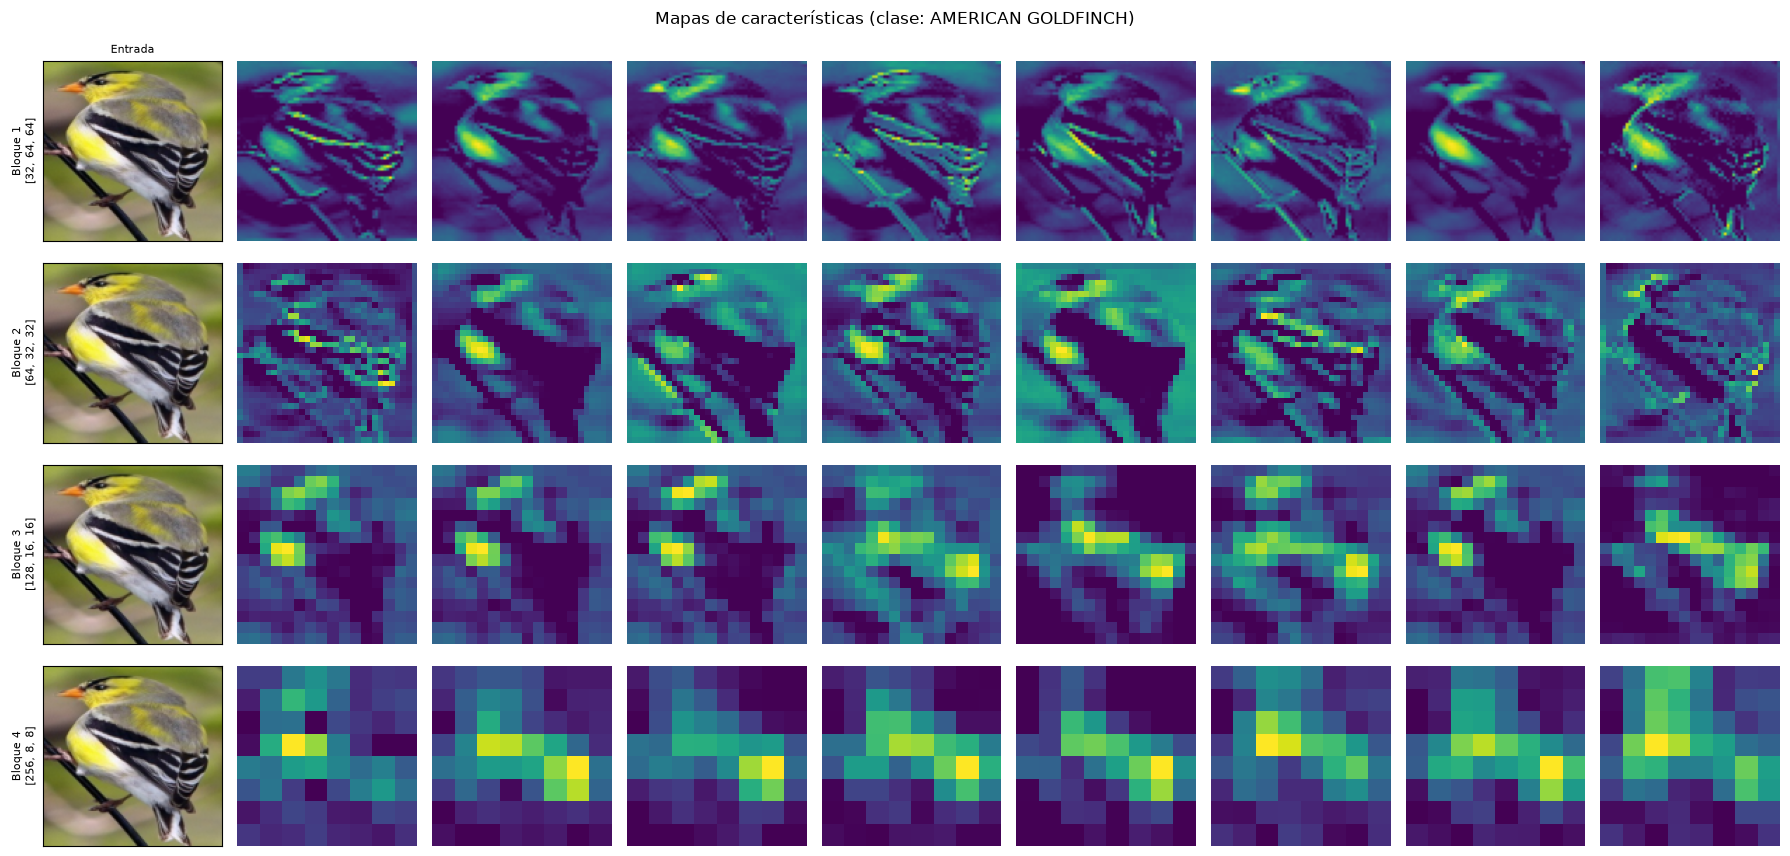

In [22]:
model.eval()
image, label = loader.test_dataset[int(sel_correct[0])]
with torch.no_grad():
    maps = [m[0].cpu() for m in model.features(image.unsqueeze(0).to(device))]

n_show = 8
fig, axes = plt.subplots(len(maps), n_show + 1, figsize=(2 * (n_show + 1), 2.2 * len(maps)))
for b, fmap in enumerate(maps):
    axes[b, 0].imshow(metrics.denormalize(image, loader.mean, loader.std))
    axes[b, 0].set_title("Entrada" if b == 0 else "", fontsize=8)
    axes[b, 0].set_ylabel(f"Bloque {b + 1}\n{list(fmap.shape)}", fontsize=8)
    axes[b, 0].set_xticks([]); axes[b, 0].set_yticks([])
    top = fmap.mean(dim=(1, 2)).argsort(descending=True)[:n_show]     # canales más activados
    for k, ch in enumerate(top):
        axes[b, k + 1].imshow(fmap[ch], cmap="viridis")
        axes[b, k + 1].axis("off")
plt.suptitle(f"Mapas de características (clase: {classes[label]})")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/mapas_caracteristicas.png", dpi=120)
plt.show()

### Pregunta 1: ¿Qué características se espera que aprendan las capas convolucionales?

El **campo receptivo** de cada neurona crece con la profundidad (con kernels 3×3 y pooling 2×2): **3 px** en Conv1, **8 px** en Conv2, **18 px** en Conv3 y **46 px** a la salida del bloque 4, es decir, más de un tercio de la imagen de 128 px. Esto determina qué tan "grande" o compuesto puede ser el patrón que detecta cada capa.

- **Primeras capas (Bloque 1, 32 filtros):** patrones simples y locales, como **bordes** en distintas orientaciones, cambios de intensidad y **manchas de color**. En los mapas de arriba se ve el contorno del ave y de la rama, las franjas blancas/negras del ala y la mancha amarilla del pecho: son detectores parecidos a los filtros Sobel vistos en clase, pero aprendidos.
- **Capas intermedias (Bloques 2–3, 64 y 128 filtros):** combinaciones de bordes en **texturas y partes**, como el patrón rayado del ala, la textura del plumaje, el contorno de la cabeza o el pico, y zonas de color uniforme. Los mapas de 32×32 y 16×16 se activan por **regiones** (cabeza, pecho, ala) en lugar de bordes finos.
- **Capas más profundas (Bloque 4, 256 filtros, 8×8):** características **abstractas y específicas de la tarea**. Cada celda resume una región grande y detecta la presencia de partes discriminativas ("pecho amarillo", "ala con barras", "disco facial", "cuello rosado"), sin importar su ubicación exacta. Los mapas ya no se parecen a la imagen. La combinación de estas activaciones es lo que el clasificador (FC1 → FC2) usa para separar las 6 especies.

### Pregunta 2: ¿Cuál es el propósito del pooling en esta arquitectura?

Cada bloque termina con un **MaxPool 2×2 con stride 2**, que se aplica 4 veces: **128 → 64 → 32 → 16 → 8**.

1. **Reducir el tamaño espacial y el costo computacional:** cada pooling reduce 4 veces el número de activaciones. Así, la convolución siguiente opera sobre mapas más pequeños, aunque tenga más filtros.
2. **Controlar el número de parámetros del clasificador:** gracias al pooling, el Flatten produce 256×8×8 = **16 384** valores y FC1 tiene 2,1 M de parámetros. Sin pooling, el Flatten tendría 256×128×128 = 4 194 304 valores y **FC1 tendría ≈ 537 millones de parámetros**, imposible de entrenar con 567 imágenes.
3. **Aumentar el campo receptivo:** al duplicar el paso entre neuronas, las capas siguientes "ven" regiones cada vez más grandes con los mismos kernels 3×3. Por eso el bloque 4 llega a 46 px de campo receptivo.
4. **Invariancia a pequeñas traslaciones y robustez:** el max pooling conserva la activación más fuerte de cada ventana 2×2, de modo que un patrón (un ojo, una franja del ala) se detecta aunque se desplace unos píxeles. Esto es útil porque las aves aparecen en distintas posiciones y poses, y además actúa como una regularización leve.

In [23]:
# Pregunta 3: CNN vs. red completamente conectada sobre todos los píxeles
input_size = IMG_SIZE * IMG_SIZE * 3
mlp = MLPModel(input_size, len(classes))      # MLP del código base: entrada -> 512 -> 512 -> 6

cnn_params = count_parameters(model)
mlp_params = count_parameters(mlp)
conv_params = sum(p.numel() for n, p in model.named_parameters() if n.startswith(("conv", "bn")))
mlp_first   = sum(p.numel() for p in mlp.fc1.parameters())

orig_input = 224 * 224 * 3
comparison = pd.DataFrame({
    "Modelo": [
        "CNN propia (completa)",
        "  - solo bloques convolucionales",
        "MLP 128×128×3 → 512 → 512 → 6",
        "  - solo la primera capa densa",
        "MLP 224×224×3 (tamaño original) → 512 → 512 → 6",
    ],
    "Parámetros": [
        cnn_params, conv_params, mlp_params, mlp_first,
        count_parameters(MLPModel(orig_input, len(classes))),
    ],
})
comparison["Veces la CNN"] = comparison["Parámetros"] / cnn_params
print(f"Entradas del MLP: {IMG_SIZE}×{IMG_SIZE}×3 = {input_size:,} píxeles")
comparison

Entradas del MLP: 128×128×3 = 49,152 píxeles


,Modelo,Parámetros,Veces la CNN
0,CNN propia (completa),2487430,1.0000
1,- solo bloques convolucionales,389376,0.1565
2,MLP 128×128×3 → 512 → 512 → 6,25432070,10.2242
3,- solo la primera capa densa,25166336,10.1174
4,MLP 224×224×3 (tamaño original) → 512 → 512 → 6,77336582,31.0910


### Pregunta 3: ¿Qué ocurriría con el número de parámetros si las capas convolucionales se reemplazaran por capas completamente conectadas que procesen todos los píxeles?

**El número de parámetros se dispararía.** En una capa densa, cada neurona se conecta a **todos** los píxeles, así que sus pesos crecen proporcionalmente al tamaño de la imagen:

- Entrada aplanada: 128 × 128 × 3 = **49 152** valores.
- Solo la primera capa densa del MLP del curso (512 neuronas): 49 152 × 512 + 512 = **25 166 336 parámetros**, es decir, **≈ 10 veces la CNN completa** (2 487 430).
- MLP completo (49 152 → 512 → 512 → 6): **25,4 M** de parámetros (10,2×).
- Con las imágenes en su tamaño original (224×224×3 = 150 528 entradas): **77,3 M** de parámetros (31×), el mismo cálculo de la diapositiva "¿Por qué no usar una red neuronal tradicional?".

En cambio, **todos los bloques convolucionales de la CNN suman solo 389 376 parámetros (15,7 % del modelo)**, gracias a la **conectividad local** y a los **pesos compartidos**: Conv1 tiene 3×3×3×32 + 32 = 896 pesos, sin importar si la imagen es de 128 o de 224 píxeles, porque el mismo filtro recorre toda la imagen. El efecto se ve incluso dentro de nuestra CNN: la única capa densa grande (FC1) concentra el 84 % de los parámetros.

**Consecuencias de usar solo capas densas:**
- Con 567 imágenes de entrenamiento y decenas de millones de parámetros, el modelo **memorizaría** el conjunto de entrenamiento (sobreajuste severo), además de requerir mucha más memoria y cómputo.
- **Se pierde la estructura espacial:** al aplanar, píxeles vecinos dejan de estar relacionados y la red tendría que aprender un detector distinto para el mismo patrón (p. ej. un ojo) en cada posición de la imagen. Una CNN lo aprende una sola vez y lo reutiliza en toda la imagen.

## Conclusiones

- Se diseñó y entrenó desde cero una CNN de 4 bloques convolucionales (2,49 M de parámetros), **sin transfer learning, sin modelos preentrenados y sin data augmentation**, que alcanza **95,9 % de accuracy, F1 macro ≈ 0,96 y AUC‑ROC ≈ 0,998** en un conjunto de prueba que no se usó en ninguna decisión del entrenamiento.
- Las curvas muestran convergencia rápida (≈ 90 % de validación en 13 épocas) y un sobreajuste leve a partir de la época ~21, que se controló con BatchNorm, Dropout, weight decay y la selección del mejor checkpoint por Validation Loss.
- Los pocos errores se concentran en especies con **paletas de color similares** (jilguero pálido ↔ lechuza, flamenco ↔ abejaruco carmín). Esto indica que el modelo depende mucho del color; más resolución o profundidad y más datos reales serían los siguientes pasos para mejorar.
- La comparación con un MLP confirma la ventaja de las convoluciones: con **10 veces menos parámetros** que una sola capa densa sobre los píxeles, la CNN aprovecha la estructura espacial de la imagen mediante filtros locales y pesos compartidos.